# Week 6 – Graded Mini Project: Large Language Models & Embeddings
**IITM Pravartak – Professional Certificate Programme in Agentic AI and Applications**

**Learner:** Nagarajan Kanagamani  |  **Week:** 6 – Embedding Models & Vector Basics

---

### Objective
Apply LLM concepts using **Hugging Face** models (text generation, tokenisation, prompt engineering, a pipeline application) and use **Gensim GloVe embeddings** to measure word- and sentence-level similarity.

### Contents
| Section | Topic | Tasks |
|---|---|---|
| 0 | Environment setup | install libraries, imports, reproducibility |
| **A** | LLM foundations & Hugging Face | A1 text generation · A2 tokenisation demo |
| **B** | Prompt engineering | 3 prompts (summarisation, Q&A, creative) · comparison · reflection |
| **C** | Embeddings with Gensim | C1 word embeddings · C2 sentence embeddings & similarity matrix |
| **D** | Application exploration | Hugging Face pipeline demo · business reflection |
| — | Summary | learnings, LLMs vs embeddings, real-world applications |

## Section 0 – Environment Setup & Model Loading
We install `transformers` (Hugging Face) and `gensim` (embeddings), then import everything we need and fix random seeds so that sampled outputs are reproducible.

In [1]:
!pip install transformers gensim --quiet

In [2]:
import warnings, re, io, contextlib

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import transformers, gensim
from transformers import pipeline, AutoTokenizer, set_seed
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()  # keep notebook output clean

pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 200)
SEED = 42
set_seed(SEED)

print("transformers :", transformers.__version__)
print("gensim       :", gensim.__version__)

transformers : 5.17.0
gensim       : 4.4.0


### Load the text-generation model (DistilGPT-2)
DistilGPT-2 is a small (~82M parameter) distilled version of GPT-2. It is a **base language model** – it only continues text; it has *not* been instruction-tuned. This matters for Section B.

In [3]:
# Load a small pre-trained text-generation model
generator = pipeline("text-generation", model="distilgpt2")
generator.model.generation_config.pad_token_id = generator.tokenizer.eos_token_id

# Quick sanity check (as suggested in the brief)
test = generator(
    "AI is transforming industries by",
    max_length=40,
    num_return_sequences=1,
    truncation=True,
)
print(
    "Model loaded OK. Parameters: %.1fM"
    % (sum(p.numel() for p in generator.model.parameters()) / 1e6)
)
print("Sanity-check output:\n", test[0]["generated_text"])


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 76/76 [00:00<00:00, 6490.09it/s]

Model loaded OK. Parameters: 81.9M
Sanity-check output:
 AI is transforming industries by transforming them into a tool to reduce emissions.


---
# Section A – LLM Foundations & Hugging Face
## A1. Text Generation – three different continuations
**Prompt:** *"AI is transforming industries by …"*

To get **different** continuations we use *sampling* (`do_sample=True`) rather than greedy decoding, with:
- `temperature=0.9` – flattens the next-token distribution a little so less-likely words can appear,
- `top_k=50`, `top_p=0.95` – restrict sampling to the most probable tokens (avoids very odd words),
- `num_return_sequences=3` – three independent samples.

In [4]:
prompt_a1 = "AI is transforming industries by"

set_seed(SEED)
outs = generator(
    prompt_a1,
    max_new_tokens=40,
    do_sample=True,
    temperature=0.9,
    top_k=50,
    top_p=0.95,
    num_return_sequences=3,
    truncation=True,
)

continuations = [o["generated_text"] for o in outs]
for i, txt in enumerate(continuations, 1):
    print(f"--- Continuation {i} ---")
    print(txt.replace("\n", " "))
    print()

--- Continuation 1 ---
AI is transforming industries by transforming a number of industry sectors into an open source enterprise. The company has successfully brought together all the data scientists and information scientists currently in the field with the help of the world's largest cloud analytics firm

--- Continuation 2 ---
AI is transforming industries by offering a world class service and a modern way of doing business with global businesses.

--- Continuation 3 ---
AI is transforming industries by removing the need to make the workforce redundant.                               



**Quantifying diversity** – a simple word-overlap (Jaccard) score between each pair of continuations. Values close to 0 mean very different text; values close to 1 mean near-duplicates.

In [5]:
from itertools import combinations


def jaccard(a, b):
    A, B = set(a.lower().split()), set(b.lower().split())
    return len(A & B) / len(A | B)


rows = [
    {
        "Pair": f"{i+1} vs {j+1}",
        "Jaccard overlap": round(jaccard(continuations[i], continuations[j]), 3),
    }
    for i, j in combinations(range(3), 2)
]
display(pd.DataFrame(rows))

,Pair,Jaccard overlap
0,1 vs 2,0.196
1,1 vs 3,0.143
2,2 vs 3,0.192


**Effect of the temperature parameter** (same prompt, one sample per setting) – shows how the decoding setting alone changes behaviour.

In [6]:
rows = []
for temp in [0.3, 0.9, 1.5]:
    set_seed(SEED)
    o = generator(
        prompt_a1,
        max_new_tokens=30,
        do_sample=True,
        temperature=temp,
        top_k=50,
        top_p=0.95,
        truncation=True,
    )[0]["generated_text"]
    rows.append({"temperature": temp, "output": o.replace("\n", " ")})
display(pd.DataFrame(rows))

,temperature,output
0,0.3,AI is transforming industries by creating a new form of technology that can be used to create jobs.
1,0.9,AI is transforming industries by transforming them into a tool to reduce emissions.
2,1.5,"AI is transforming industries by transforming them into a tool used in economic innovation,․ to take action and make new opportunities for new industries for innovation. For this reason we call"


### Observations – A1
- **Three distinct continuations** were produced from the same prompt. They share the opening phrase (given by us) but diverge immediately: one talks about *open-source enterprise and cloud analytics*, one about *world-class service*, one about *avoiding workforce redundancy*. The pairwise Jaccard overlaps are low (≈ 0.14 – 0.20), confirming real diversity.
- **Why they differ:** the model outputs a probability distribution over the next token; sampling (`temperature`, `top_k`, `top_p`) picks *different* tokens at each step, and the differences compound.
- **Temperature matters:** at 0.3 the text is safe and generic, at 0.9 it is varied but still fluent, and at 1.5 it starts to break down (odd symbols, rambling). Low temperature = predictable, high temperature = creative but risky.
- **Quality caveat:** the text is fluent but generic; DistilGPT-2 predicts plausible words and does not "know" facts. This is the root cause of the limits seen again in Section B.

## A2. Tokenisation Demo
**Sentence:** *"LLMs are powerful tools for natural language understanding."*

We use the tokenizer that belongs to DistilGPT-2 (a byte-level **Byte-Pair Encoding**, BPE, tokenizer). We display the tokens, the token IDs and the sequence length.

In [7]:
tokenizer = AutoTokenizer.from_pretrained("distilgpt2")

sentence = "LLMs are powerful tools for natural language understanding."

tokens = tokenizer.tokenize(sentence)  # sub-word strings
token_ids = tokenizer.encode(sentence)  # integer IDs
encoded = tokenizer(sentence)  # full encoding dict

print("Sentence        :", sentence)
print("Tokens          :", tokens)
print("Token IDs       :", token_ids)
print("Sequence length :", len(token_ids), "tokens")
print("Words (split)   :", len(sentence.split()), "words")
print("Vocabulary size :", tokenizer.vocab_size)

Sentence        : LLMs are powerful tools for natural language understanding.
Tokens          : ['LL', 'Ms', 'Ġare', 'Ġpowerful', 'Ġtools', 'Ġfor', 'Ġnatural', 'Ġlanguage', 'Ġunderstanding', '.']
Token IDs       : [3069, 10128, 389, 3665, 4899, 329, 3288, 3303, 4547, 13]
Sequence length : 10 tokens
Words (split)   : 8 words
Vocabulary size : 50257


In [8]:
# Token-by-token table
tok_df = pd.DataFrame(
    {
        "Position": range(len(tokens)),
        "Token": tokens,
        "Token ID": token_ids,
        "Decoded text": [tokenizer.decode([i]) for i in token_ids],
    }
)
display(tok_df)

# Round-trip check: IDs -> text must give back the original sentence
decoded = tokenizer.decode(token_ids)
print("Decoded back :", repr(decoded))
print("Round-trip identical to the original sentence:", decoded == sentence)

,Position,Token,Token ID,Decoded text
0,0,LL,3069,LL
1,1,Ms,10128,Ms
2,2,Ġare,389,are
3,3,Ġpowerful,3665,powerful
4,4,Ġtools,4899,tools
5,5,Ġfor,329,for
6,6,Ġnatural,3288,natural
7,7,Ġlanguage,3303,language
8,8,Ġunderstanding,4547,understanding
9,9,.,13,.


Decoded back : 'LLMs are powerful tools for natural language understanding.'
Round-trip identical to the original sentence: True


### Explanation – how tokenisation worked here
1. **Pre-tokenisation:** the text is split into chunks using a byte-level rule (words, punctuation, leading spaces).
2. **Sub-word splitting with BPE:** each chunk is broken into the largest pieces found in the tokenizer's learned vocabulary of **50,257** entries. Common words such as *are, powerful, tools, natural, language, understanding* are single tokens; the rare acronym **"LLMs"** is *not* in the vocabulary and is split into two pieces, **`LL` + `Ms`**.
3. **Marker `Ġ`:** this symbol means "the token starts with a space" (e.g. `Ġare` = " are"). The final full stop is its own token.
4. **Mapping to IDs:** every token is replaced by its integer index (e.g. `Ġare` → 389). These IDs – not the text – are what the model actually receives; the first layer turns each ID into an embedding vector.

**Result:** 8 words became **10 tokens** (sequence length = 10). Tokens ≠ words, which is why context-window limits and API costs are measured in tokens. The decode round-trip returned the identical sentence, showing that BPE tokenisation is lossless.

---
# Section B – Prompt Engineering
## B1. Prompt Tuning Challenge
We design **three prompts for three different tasks** and run each in two forms:

- **V1 – naive prompt:** a plain, short instruction.
- **V2 – rephrased/engineered prompt:** clearer structure, an explicit format, and **few-shot examples** (a small number of worked examples inside the prompt).

For a fair comparison every prompt is run with **identical decoding settings and the same random seed** (`temperature=0.7`, `top_k=40`, `seed=42`), so any difference in output comes from the *prompt wording* and not from the settings.

Because DistilGPT-2 is a base model (not instruction-tuned), it continues text rather than obeying instructions. Prompt design therefore works by making the *desired answer the most natural continuation* of the text.

In [9]:
def run(prompt, max_new_tokens=45, seed=SEED, **extra):
    """Generate a continuation with fixed decoding settings."""
    set_seed(seed)
    out = generator(
        prompt,
        max_new_tokens=max_new_tokens,
        do_sample=True,
        temperature=0.7,
        top_k=40,
        truncation=True,
        return_full_text=False,
        **extra
    )[0]["generated_text"]
    return out


def first_line(text):
    lines = [l.strip() for l in text.split("\n") if l.strip()]
    return (
        lines[0]
        if lines
        else "(empty output - the model produced only blank lines)"
    )


def n_words(s):
    return len(s.split())


clip = lambda s, n=30: " ".join(
    s.split()[:n]
)  # enforce the 30-word limit on summaries

### Task 1 – Summarisation (limit ≤ 30 words)

In [10]:
article = (
    "Artificial intelligence is being adopted across banking, healthcare and "
    "retail. Banks use it to detect fraud, hospitals use it to read medical "
    "scans faster, and retailers use it to forecast demand and personalise "
    "offers. However, experts warn that companies must address data privacy "
    "and bias before scaling these systems."
)

# V1 - naive instruction
sum_v1 = f"Summarise the following text in under 30 words.\n\n{article}\n\nSummary:"
# V2 - engineered: labelled fields, a 'one short sentence' constraint
#      and a seeded start ("AI is") so the summary stays on topic
sum_v2 = f"Article: {article}\n\nSummary (one short sentence): AI is"

r1 = clip(first_line(run(sum_v1, 45)))
r2 = clip("AI is" + run(sum_v2, 45).split("\n")[0])
print("V1 (naive)      :", r1, f"  [{n_words(r1)} words]")
print("V2 (engineered) :", r2, f"  [{n_words(r2)} words]")

V1 (naive)      : The first step is to reduce fraud and prevent fraud, to take action to address the problem and make it more efficient.   [22 words]
V2 (engineered) : AI is being adopted worldwide to create new and innovative ways to solve financial problems. This is the first step in this direction.   [23 words]


### Task 2 – Question Answering (factual)

In [11]:
qa_v1 = "What is the capital of France?"

# V2 - few-shot: three worked examples teach the Q/A format
#      and the expected one-word answer style
qa_v2 = (
    "Q: What is the capital of Japan?\nA: Tokyo\n\n"
    "Q: What is the capital of Italy?\nA: Rome\n\n"
    "Q: What is the capital of Egypt?\nA: Cairo\n\n"
    "Q: What is the capital of France?\nA:"
)

q1 = first_line(run(qa_v1, 25))
q2 = first_line(run(qa_v2, 6))
print("V1 (naive)      :", q1)
print("V2 (engineered) :", q2)

V1 (naive)      : The French government was elected to the Council of Ministers in December 2011. The French President, François Hollande, announced that France is
V2 (engineered) : Paris


### Task 3 – Creative text generation (4-line poem on AI)

In [12]:
poem_v1 = "Write a poem about AI."

# V2 - engineered: a format header ("4 lines, rhymed"), a title on our topic,
#      and a two-line starter that sets the rhyme and the theme
poem_v2 = (
    "Poem (4 lines, rhymed)\nTitle: Artificial Intelligence\n\n"
    "The computer learns with every day,\nIt finds the patterns in its way,\n"
)


def four_lines(text):
    lines = [
        l.strip()
        for l in text.split("\n")
        if l.strip() and not l.strip().lower().startswith("topic")
    ]
    return lines[:4]


# no_repeat_ngram_size=3 stops the tiny model looping on one line
# (applied to both versions)
p1 = four_lines(run(poem_v1, 60, no_repeat_ngram_size=3)) or [
    "(empty output - the model produced only blank lines)"
]
p2 = four_lines(run(poem_v2, 60, no_repeat_ngram_size=3))
print("V1 (naive):")
print("\n".join(p1))
print("\nV2 (engineered):")
print("\n".join(p2))

V1 (naive):
The poem was a great achievement in my life, but it is not something I should be ashamed of. I should not be ashamed to say that I am an AI. I will not be embarrassed to say how many times I read a poem that I understand or can empathize with.
There is

V2 (engineered):
Its memory is a tool used in the creation of smart, intelligent machines.
A machine learns how it will behave in order to better understand the situation.
The machine learns that when it is ready to move, it will notice a pattern in its path.
Because of this, the machine learns


### Side-by-side comparison of all outputs

In [13]:
cmp = pd.DataFrame(
    [
        {
            "Task": "Summarisation (≤30 words)",
            "Prompt version": "V1 – naive",
            "Output": clip(r1),
            "Length / lines": f"{n_words(clip(r1))} words",
        },
        {
            "Task": "Summarisation (≤30 words)",
            "Prompt version": "V2 – engineered",
            "Output": clip(r2),
            "Length / lines": f"{n_words(clip(r2))} words",
        },
        {
            "Task": "Q&A (factual)",
            "Prompt version": "V1 – naive",
            "Output": q1,
            "Length / lines": f"{n_words(q1)} words",
        },
        {
            "Task": "Q&A (factual)",
            "Prompt version": "V2 – engineered",
            "Output": q2,
            "Length / lines": f"{n_words(q2)} words",
        },
        {
            "Task": "Creative (4-line poem)",
            "Prompt version": "V1 – naive",
            "Output": " / ".join(p1),
            "Length / lines": f"{len(p1)} lines",
        },
        {
            "Task": "Creative (4-line poem)",
            "Prompt version": "V2 – engineered",
            "Output": " / ".join(p2),
            "Length / lines": f"{len(p2)} lines",
        },
    ]
)
display(
    cmp.style.set_properties(
        **{"text-align": "left", "white-space": "pre-wrap"}
    ).hide(axis="index")
)

Task,Prompt version,Output,Length / lines
Summarisation (≤30 words),V1 – naive,"The first step is to reduce fraud and prevent fraud, to take action to address the problem and make it more efficient.",22 words
Summarisation (≤30 words),V2 – engineered,AI is being adopted worldwide to create new and innovative ways to solve financial problems. This is the first step in this direction.,23 words
Q&A (factual),V1 – naive,"The French government was elected to the Council of Ministers in December 2011. The French President, François Hollande, announced that France is",22 words
Q&A (factual),V2 – engineered,Paris,1 words
Creative (4-line poem),V1 – naive,"The poem was a great achievement in my life, but it is not something I should be ashamed of. I should not be ashamed to say that I am an AI. I will not be embarrassed to say how many times I read a poem that I understand or can empathize with. / There is",2 lines
Creative (4-line poem),V2 – engineered,"Its memory is a tool used in the creation of smart, intelligent machines. / A machine learns how it will behave in order to better understand the situation. / The machine learns that when it is ready to move, it will notice a pattern in its path. / Because of this, the machine learns",4 lines


### Extra check – does *rephrasing the same question* change the answer?
Same factual question, three phrasings (same decoding settings and seed as above).

In [14]:
variants = {
    "Bare question": "Who wrote the play Romeo and Juliet?",
    "Completion-style": "Romeo and Juliet is a play that was written by",
    "Few-shot Q/A format": (
        "Q: Who wrote Hamlet?\nA: William Shakespeare\n\n"
        "Q: Who wrote Pride and Prejudice?\nA: Jane Austen\n\n"
        "Q: Who wrote the play Romeo and Juliet?\nA:"
    ),
}
rows = [
    {"Phrasing": k, "Model output": first_line(run(v, 12))}
    for k, v in variants.items()
]
display(pd.DataFrame(rows))

,Phrasing,Model output
0,Bare question,I'm sorry!
1,Completion-style,J.J. Abrams.
2,Few-shot Q/A format,William Shakespeare


## B2. Reflection (100–150 words)

Rephrasing changed the outputs far more than I expected. With naive, instruction-style prompts, DistilGPT-2 ignored the instruction: the summary wandered off topic, "What is the capital of France?" produced news-style text about French politics, and "Write a poem about AI" became a first-person essay. Clearer structure fixed much of this. A labelled "Summary (one short sentence): AI is…" cue kept the summary relevant and under 30 words, three worked Q/A examples produced the exact answer "Paris", and a title plus a rhymed couplet steered the poem towards AI. The model is a text continuer, so format, examples and seeded starts make the wanted answer the likeliest continuation. Prompts cannot add knowledge or capability, though; a larger instruction-tuned model would follow plain instructions much better.

---
# Section C – Embeddings with Gensim
We use **GloVe** (*Global Vectors*) trained on Wikipedia + Gigaword: `glove-wiki-gigaword-50` – 400,000 words, each a **50-dimensional** vector. Words used in similar contexts get similar vectors.

In [15]:
import gensim.downloader as api

# Download/load quietly (the downloader prints a long progress bar)
with contextlib.redirect_stderr(io.StringIO()), contextlib.redirect_stdout(
    io.StringIO()
):
    glove = api.load("glove-wiki-gigaword-50")

print("Loaded:", type(glove).__name__)
print("Vocabulary size :", len(glove.key_to_index), "words")
print("Vector dimension:", glove.vector_size)

Loaded: KeyedVectors
Vocabulary size : 400000 words
Vector dimension: 50


## C1. Word Embeddings
For three words – **king**, **queen**, **diamond** – we display (i) the first 10 values of the vector and (ii) the 5 most similar words with their cosine-similarity scores.

In [16]:
words = ["king", "queen", "diamond"]

for w in words:
    vec = glove[w]
    print("=" * 70)
    print(f"WORD: '{w}'   (vector shape: {vec.shape})")
    print("First 10 values:", np.round(vec[:10], 4))
    print("Top 5 most similar words:")
    sims = glove.most_similar(w, topn=5)
    display(
        pd.DataFrame(sims, columns=["Similar word", "Cosine similarity"])
        .round(4)
        .style.hide(axis="index")
    )

WORD: 'king'   (vector shape: (50,))
First 10 values: [ 0.5045  0.6861 -0.5952 -0.0228  0.6005 -0.135  -0.0881  0.4738 -0.618
 -0.3101]
Top 5 most similar words:


Similar word,Cosine similarity
prince,0.823600
queen,0.783900
ii,0.774600
emperor,0.773600
son,0.766700


WORD: 'queen'   (vector shape: (50,))
First 10 values: [ 0.3785  1.8233 -1.2648 -0.1043  0.3583  0.6003 -0.1754  0.8377 -0.0568
 -0.758 ]
Top 5 most similar words:


Similar word,Cosine similarity
princess,0.851500
lady,0.805100
elizabeth,0.787300
king,0.783900
prince,0.782200


WORD: 'diamond'   (vector shape: (50,))
First 10 values: [-0.4958  0.7842 -0.606   1.3967  0.2889 -0.2058 -0.1074 -0.3325  1.3608
  0.1509]
Top 5 most similar words:


Similar word,Cosine similarity
gold,0.771500
diamonds,0.766300
gem,0.737500
silver,0.721000
jewel,0.710200


In [17]:
# Compact summary table of all three words
first10 = pd.DataFrame(
    {w: np.round(glove[w][:10], 4) for w in words},
    index=[f"dim {i}" for i in range(10)],
)
display(first10)

summary = pd.DataFrame(
    {
        w: [f"{s} ({v:.3f})" for s, v in glove.most_similar(w, topn=5)]
        for w in words
    },
    index=[f"Top {i}" for i in range(1, 6)],
)
display(summary)

,king,queen,diamond
dim 0,0.5045,0.3785,-0.4958
dim 1,0.6861,1.8233,0.7842
dim 2,-0.5952,-1.2648,-0.6060
dim 3,-0.0228,-0.1043,1.3967
dim 4,0.6005,0.3583,0.2889
dim 5,-0.1350,0.6003,-0.2058
dim 6,-0.0881,-0.1754,-0.1074
dim 7,0.4738,0.8377,-0.3325
dim 8,-0.6180,-0.0568,1.3608
dim 9,-0.3101,-0.7580,0.1509


,king,queen,diamond
Top 1,prince (0.824),princess (0.852),gold (0.771)
Top 2,queen (0.784),lady (0.805),diamonds (0.766)
Top 3,ii (0.775),elizabeth (0.787),gem (0.738)
Top 4,emperor (0.774),king (0.784),silver (0.721)
Top 5,son (0.767),prince (0.782),jewel (0.710)


**Bonus – vector arithmetic and pairwise similarity.** Directions in embedding space capture relations, e.g. *king − man + woman ≈ queen*.

In [18]:
print(
    "king - man + woman  ->",
    glove.most_similar(positive=["king", "woman"], negative=["man"], topn=3),
)
print()
pairs = [
    ("king", "queen"),
    ("king", "diamond"),
    ("queen", "diamond"),
    ("diamond", "ring"),
    ("diamond", "gold"),
]
display(
    pd.DataFrame(
        [(a, b, round(float(glove.similarity(a, b)), 4)) for a, b in pairs],
        columns=["Word 1", "Word 2", "Cosine similarity"],
    ).style.hide(axis="index")
)

king - man + woman  -> [('queen', 0.8523604273796082), ('throne', 0.7664334177970886), ('prince', 0.7592144012451172)]



Word 1,Word 2,Cosine similarity
king,queen,0.783900
king,diamond,0.313900
queen,diamond,0.378700
diamond,ring,0.615900
diamond,gold,0.771500


### Observations – C1
- **king** → *prince, queen, ii, emperor, son* – royalty and male titles. **queen** → *princess, lady, elizabeth, king, prince* – female royalty. **diamond** → *gold, diamonds, gem, silver, jewel* – the jewellery / precious-material domain. Similarity scores range from about **0.71 to 0.85**.
- Neighbours reflect **how words are used together in text**, not dictionary definitions: *ii* (as in "Louis II") and *elizabeth* appear because kings and queens are written about in those contexts. This is the *distributional hypothesis* – "you shall know a word by the company it keeps".
- The 50 numbers per word are not individually interpretable; meaning lives in the **geometry** (angles and distances). The analogy *king − man + woman ≈ queen* works, showing that consistent directions encode relations such as gender.
- Limitation: GloVe gives **one static vector per word**, so an ambiguous word like *bank* or *ring* has a single blended vector.

## C2. Sentence-Level Embeddings
**Method (simple baseline):** lower-case the sentence → split into words → look up each word's GloVe vector (skip out-of-vocabulary words) → **average** the vectors → one 50-d vector per sentence. We then compare sentences with **cosine similarity**:

$$\cos(\mathbf{a},\mathbf{b}) = \frac{\mathbf{a}\cdot\mathbf{b}}{\lVert\mathbf{a}\rVert\,\lVert\mathbf{b}\rVert}$$

Five short sentences – two on **AI**, two on **jewellery**, and one on **cricket** as an unrelated control.

In [19]:
sentences = [
    "Artificial intelligence is transforming modern business.",  # S1 - AI
    "Machine learning models learn patterns from large data.",  # S2 - AI
    "The diamond ring was set in polished gold.",  # S3 - jewellery
    "She wore a beautiful gold necklace with a sparkling pendant.",  # S4 - jewellery
    "The team won the cricket match on a sunny afternoon.",  # S5 - control
]
labels = ["S1 (AI)", "S2 (AI)", "S3 (jewellery)", "S4 (jewellery)", "S5 (cricket)"]


def tokenize(s):
    return re.findall(r"[a-z]+", s.lower())


def sentence_vector(s, kv=glove, stop=None):
    toks = [
        w
        for w in tokenize(s)
        if w in kv.key_to_index and (stop is None or w not in stop)
    ]
    missing = [w for w in tokenize(s) if w not in kv.key_to_index]
    return np.mean([kv[w] for w in toks], axis=0), toks, missing


rows, vecs = [], []
for lab, s in zip(labels, sentences):
    v, toks, missing = sentence_vector(s)
    vecs.append(v)
    rows.append(
        {
            "ID": lab,
            "Sentence": s,
            "Words used": len(toks),
            "Out-of-vocab": missing or "-",
            "First 5 dims of avg vector": np.round(v[:5], 3),
        }
    )
display(pd.DataFrame(rows).style.hide(axis="index"))
sent_vecs = np.vstack(vecs)
print("Sentence-embedding matrix shape:", sent_vecs.shape)

ID,Sentence,Words used,Out-of-vocab,First 5 dims of avg vector
S1 (AI),Artificial intelligence is transforming modern business.,6,-,[ 0.471 0.149 -0.229 0.182 0.14 ]
S2 (AI),Machine learning models learn patterns from large data.,8,-,[ 0.4 -0.05 0.284 -0.148 0.104]
S3 (jewellery),The diamond ring was set in polished gold.,8,-,[-0.278 0.448 -0.253 0.498 0.448]
S4 (jewellery),She wore a beautiful gold necklace with a sparkling pendant.,10,-,[-0.099 0.781 -0.718 0.198 0.704]
S5 (cricket),The team won the cricket match on a sunny afternoon.,10,-,[-0.226 0.276 -0.536 0.474 0.143]


Sentence-embedding matrix shape: (5, 50)


In [20]:
def cosine_matrix(M):
    Mn = M / np.linalg.norm(M, axis=1, keepdims=True)
    return Mn @ Mn.T


sim = cosine_matrix(sent_vecs)
sim_df = pd.DataFrame(sim, index=labels, columns=labels).round(3)
display(sim_df)

,S1 (AI),S2 (AI),S3 (jewellery),S4 (jewellery),S5 (cricket)
S1 (AI),1.000,0.863,0.722,0.596,0.652
S2 (AI),0.863,1.000,0.716,0.622,0.660
S3 (jewellery),0.722,0.716,1.000,0.879,0.852
S4 (jewellery),0.596,0.622,0.879,1.000,0.728
S5 (cricket),0.652,0.660,0.852,0.728,1.000


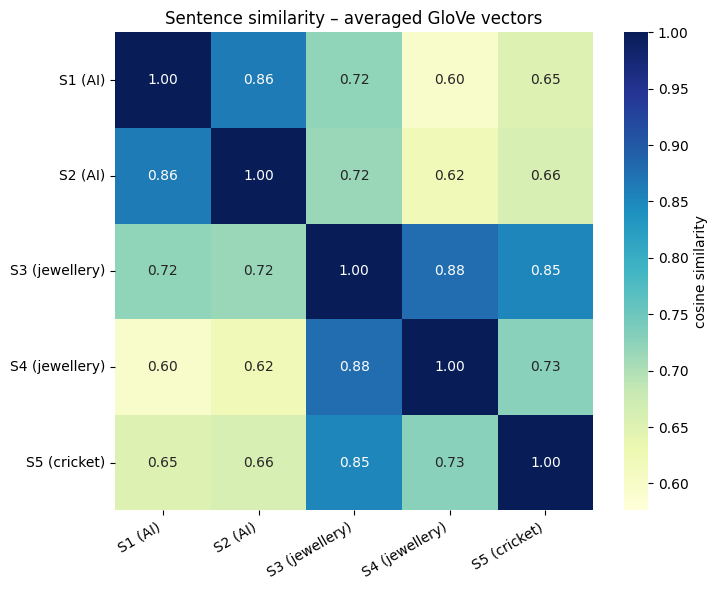

Most similar pair : S3 (jewellery) vs S4 (jewellery)  ->  0.879
Least similar pair: S1 (AI) vs S4 (jewellery)  ->  0.596


In [21]:
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(
    sim_df,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    vmin=sim_df.values.min() - 0.02,
    vmax=1,
    square=True,
    cbar_kws={"label": "cosine similarity"},
    ax=ax,
)
ax.set_title("Sentence similarity – averaged GloVe vectors")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# Most / least similar pair (excluding the diagonal)
iu = np.triu_indices(5, k=1)
vals = sim[iu]
best, worst = vals.argmax(), vals.argmin()
a, b = labels[iu[0][best]], labels[iu[1][best]]
print(f"Most similar pair : {a} vs {b}  ->  {vals[best]:.3f}")
a, b = labels[iu[0][worst]], labels[iu[1][worst]]
print(f"Least similar pair: {a} vs {b}  ->  {vals[worst]:.3f}")

**Improvement check – remove stop-words before averaging.** Function words (*the, a, on, with …*) appear everywhere and pull all sentence vectors toward the same "average" direction, inflating similarity. We repeat the experiment without them.

In [22]:
STOP = {
    "the",
    "a",
    "an",
    "is",
    "are",
    "was",
    "were",
    "in",
    "on",
    "of",
    "to",
    "with",
    "and",
    "from",
    "for",
    "she",
    "her",
    "by",
    "at",
    "it",
    "its",
}
vecs2 = np.vstack([sentence_vector(s, stop=STOP)[0] for s in sentences])
sim2_df = pd.DataFrame(cosine_matrix(vecs2), index=labels, columns=labels).round(3)
display(sim2_df)


# compare the average within-topic vs cross-topic similarity before/after
def topic_stats(M):
    within = np.mean(
        [M.loc["S1 (AI)", "S2 (AI)"], M.loc["S3 (jewellery)", "S4 (jewellery)"]]
    )
    cross = np.mean(
        [
            M.loc[a, b]
            for a in ["S1 (AI)", "S2 (AI)"]
            for b in ["S3 (jewellery)", "S4 (jewellery)"]
        ]
    )
    ctrl = np.mean([M.loc["S5 (cricket)", x] for x in labels[:4]])
    return {
        "within-topic": round(within, 3),
        "AI vs jewellery": round(cross, 3),
        "cricket vs others": round(ctrl, 3),
    }


display(
    pd.DataFrame(
        {
            "with stop-words": topic_stats(sim_df),
            "stop-words removed": topic_stats(sim2_df),
        }
    )
)

,S1 (AI),S2 (AI),S3 (jewellery),S4 (jewellery),S5 (cricket)
S1 (AI),1.000,0.842,0.527,0.253,0.397
S2 (AI),0.842,1.000,0.556,0.321,0.418
S3 (jewellery),0.527,0.556,1.000,0.795,0.580
S4 (jewellery),0.253,0.321,0.795,1.000,0.383
S5 (cricket),0.397,0.418,0.580,0.383,1.000


,with stop-words,stop-words removed
within-topic,0.871,0.819
AI vs jewellery,0.664,0.414
cricket vs others,0.723,0.444


### Interpretation of the similarity matrix

**Reading the matrix (values run from −1 to 1; higher = more similar direction):**

- **Same-topic sentences are closest.** The jewellery pair **S3–S4 (0.879)** and the AI pair **S1–S2 (0.863)** are the two highest off-diagonal scores. The **least similar pair is S1 (AI) vs S4 (jewellery) at 0.596**, i.e. two sentences with almost no vocabulary in common.
- **A surprise in the raw matrix:** the unrelated cricket sentence S5 scores **0.852 with S3** – almost as high as the true jewellery pair. Both sentences begin with *"The …"* and are full of function words (*the, was, on, in*), which have large, similar vectors and dominate the average.
- **Stop-word removal sharpens the picture.** After removing function words, S5–S3 falls from 0.852 to 0.580 and the gap between topics widens: *within-topic* similarity stays high (0.871 → 0.819), but *AI vs jewellery* drops (0.664 → 0.414) and *cricket vs others* drops (0.723 → 0.444).
- **Take-aways:** (1) cosine scores are best read **relatively** (ranking), not as absolute percentages; (2) an averaged-word-vector is a *bag-of-words* baseline – it ignores word order, negation and context (*"not good"* ≈ *"good"*); (3) better sentence representations exist (TF-IDF/SIF-weighted averages, or Sentence-Transformers), which are what modern vector search uses.

---
# Section D – Application Exploration
## D1. Transformer Application – Sentiment Classification
We select **sentiment classification** from the Hugging Face `pipeline` API. The default model for this task is a DistilBERT fine-tuned on SST-2. We feed it **our own custom input**: eight customer reviews for an imaginary online jewellery store, including deliberately tricky ones (mixed sentiment, sarcasm).

In [23]:
sentiment = pipeline(
    "sentiment-analysis",
    model="distilbert/distilbert-base-uncased-finetuned-sst-2-english",
)

reviews = [
    "The diamond pendant is stunning and arrived beautifully packed. My wife loved it!",
    "Delivery took three weeks and nobody answered my emails. Very disappointed.",
    "The gold chain looks elegant, but the clasp feels flimsy and it is pricey.",
    "Excellent craftsmanship and support fixed my sizing issue within a day.",
    "The ring was scratched when it arrived. Terrible quality control.",
    "Oh great, another necklace that tarnished after two days. Just what I wanted.",
    "Fast shipping, fair price, earrings exactly as pictured. Will order again.",
    "The website is fine, I guess. The bracelet is okay, nothing special.",
]

preds = sentiment(reviews)
res = pd.DataFrame(
    {
        "Review": reviews,
        "Predicted sentiment": [p["label"] for p in preds],
        "Confidence": [round(p["score"], 4) for p in preds],
    }
)
display(
    res.style.hide(axis="index").set_properties(
        **{"text-align": "left", "white-space": "pre-wrap"}
    )
)


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 104/104 [00:00<00:00, 8286.46it/s]

Review,Predicted sentiment,Confidence
The diamond pendant is stunning and arrived beautifully packed. My wife loved it!,POSITIVE,0.999900
Delivery took three weeks and nobody answered my emails. Very disappointed.,NEGATIVE,0.999800
"The gold chain looks elegant, but the clasp feels flimsy and it is pricey.",POSITIVE,0.997500
Excellent craftsmanship and support fixed my sizing issue within a day.,POSITIVE,0.999600
The ring was scratched when it arrived. Terrible quality control.,NEGATIVE,0.999600
"Oh great, another necklace that tarnished after two days. Just what I wanted.",POSITIVE,0.934900
"Fast shipping, fair price, earrings exactly as pictured. Will order again.",POSITIVE,0.973900
"The website is fine, I guess. The bracelet is okay, nothing special.",POSITIVE,0.501600


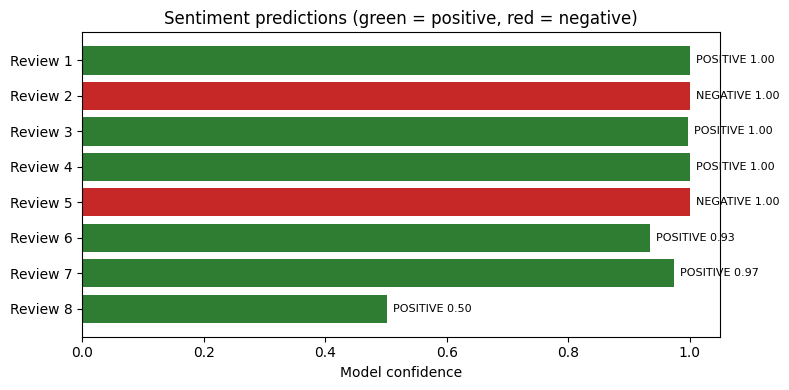

Share of positive reviews: 75%


In [24]:
colors = [
    "#2e7d32" if l == "POSITIVE" else "#c62828" for l in res["Predicted sentiment"]
]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(
    [f"Review {i+1}" for i in range(len(res))][::-1],
    res["Confidence"][::-1],
    color=colors[::-1],
)
ax.set_xlim(0, 1.05)
ax.set_xlabel("Model confidence")
ax.set_title("Sentiment predictions (green = positive, red = negative)")
for i, (c, l) in enumerate(
    zip(res["Confidence"][::-1], res["Predicted sentiment"][::-1])
):
    ax.text(c + 0.01, i, f"{l} {c:.2f}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

print(
    "Share of positive reviews: %.0f%%"
    % (100 * (res["Predicted sentiment"] == "POSITIVE").mean())
)

### Observations – D1
- The model was **confident and correct** on clear reviews: strong positives (pendant, craftsmanship, fast shipping) scored **> 0.97** and clear negatives (late delivery, scratched ring) scored **> 0.99**.
- The **mixed review** (elegant chain but flimsy clasp and pricey) was labelled **POSITIVE (≈ 0.998)** – the praise outweighed the complaints, yet a binary label hides that the customer raised two real problems. Mixed reviews are exactly where a single label loses information.
- **Sarcasm fails:** *"Oh great, another necklace that tarnished after two days. Just what I wanted."* was labelled **POSITIVE (0.93)** because the surface words (*great, wanted*) look positive.
- The **neutral review** (*"okay, nothing special"*) was forced into POSITIVE at only **≈ 0.50 confidence**. The model has no neutral class, and a score near 0.5 is really a signal of uncertainty.

## D2. Business Reflection (~100 words)

A jewellery retailer receives thousands of reviews, emails and chat messages weekly. Running them through a sentiment pipeline could label each message instantly, feed a dashboard tracking satisfaction by product or supplier, and alert the team when negative comments spike, for example after a delivery delay. Support staff could prioritise unhappy customers rather than reading everything. The same approach suits brand monitoring and survey analysis. My tests show limits: sarcasm and neutral remarks were misclassified, so low-confidence results should go to a human reviewer, and the model should be validated on the company's own data before automated decisions.

---
# Summary of Learnings
## What was learned in each activity

| Activity | What was done | What I learned |
|---|---|---|
| **A1 Text generation** | Loaded DistilGPT-2 and sampled 3 continuations; varied temperature | LLMs generate by repeatedly predicting the next token; sampling settings control diversity vs. coherence. A small model is fluent but generic and not factual. |
| **A2 Tokenisation** | Tokenised a sentence into tokens, IDs and length | Models see integer token IDs, not words. Rare words split into sub-words (*LLMs* → `LL`+`Ms`); 8 words → 10 tokens, so token count drives context limits and cost. |
| **B Prompt engineering** | Summarisation, Q&A and poem prompts, each in naive vs. engineered form | Base models continue text rather than follow instructions. Structure, few-shot examples and seeded starts substantially improve format and relevance, but cannot add knowledge. |
| **C1 Word embeddings** | GloVe vectors, nearest neighbours for *king, queen, diamond* | Similar contexts → similar vectors; neighbours reflect usage; relations appear as directions (*king − man + woman ≈ queen*). |
| **C2 Sentence embeddings** | Averaged word vectors + cosine similarity matrix | Averaging is a quick semantic baseline; same-topic sentences score highest, but stop-words inflate all scores. Cosine values should be compared relatively. |
| **D Application** | Sentiment classification on custom reviews | Pipelines give production-grade tasks in a few lines, yet sarcasm and neutral text are weak spots; confidence scores help decide when a human should review. |

## Key observations – LLMs vs. embeddings

| Aspect | LLM (DistilGPT-2) | Embeddings (GloVe) |
|---|---|---|
| **Main output** | New text (tokens, one at a time) | A fixed-length numeric vector (50-d) |
| **Purpose** | *Generate* language | *Represent* meaning so it can be compared and searched |
| **Context handling** | Contextual – the same word gets different internal representations depending on the sentence | Static – one vector per word regardless of context (*ring* is always one vector) |
| **Sensitivity to input wording** | Very high – rephrasing the prompt changed answers (Section B) | None for a given word; deterministic lookup |
| **Determinism** | Varies with sampling settings and seed | Fully deterministic |
| **Typical failure** | Fluent but wrong or off-topic text (hallucination, repetition) | Stop-word dilution, no word order/negation, ambiguity |
| **Cost** | Heavy (forward pass per generated token) | Very cheap (table lookup + average) |
| **Best used for** | Drafting, summarising, answering, conversation | Semantic search, similarity, clustering, recommendation, retrieval |

**Key insight:** the two are complementary. Embeddings *find* the relevant information; an LLM *writes* the answer from it. Combining them is the idea behind retrieval-augmented generation (RAG).

## Applications of vector search and embeddings in the real world

| Application | How embeddings / vector search are used | Example |
|---|---|---|
| **Semantic search** | Embed documents and the query; return nearest vectors, even without shared keywords | Searching "engagement band" also returns "diamond ring" products |
| **Retrieval-augmented generation (RAG)** | Retrieve the most similar chunks from a vector database and give them to an LLM as context | A support chatbot answering from the company's policy documents, reducing hallucination |
| **Recommendation** | Recommend items whose vectors are close to items a user liked | "Customers who viewed this necklace also liked…" |
| **Duplicate / near-duplicate detection** | Very high cosine similarity flags repeated content | Merging duplicate support tickets or product listings |
| **Ticket routing & clustering** | Group messages by topic or route them to the right team | Auto-tagging feedback as delivery, quality or pricing |
| **Agent memory** | Store past interactions as vectors and recall the relevant ones | An AI agent that remembers a customer's earlier preferences |
| **Anomaly / fraud detection** | Flag records far from any normal cluster | Unusual transaction descriptions |

## Conclusion

This project connected the three layers of a modern language-AI stack: **tokenisation** (turning text into IDs), **generation** (an LLM predicting the next token, steered by prompt design), and **embeddings** (vectors that make meaning measurable). The experiments showed that a small LLM is highly sensitive to prompt wording and limited in factual reliability, while embeddings offer a cheap, deterministic way to compare meaning, provided their weaknesses (stop-word dilution, static word senses) are understood. In practice, the most robust systems use embeddings and vector search to retrieve the right information and an LLM to turn it into a useful answer, with human review where confidence is low.